# Data quality

Checks on the `consumption` and `weather` tables: gaps in the time
series, missing values, and plausibility of extreme values.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from load_forecast.db import read_sql

In [2]:
gaps = read_sql(
    """
    SELECT ts AS last_before_gap,
           next_ts AS first_after_gap,
           next_ts - ts AS gap
    FROM (
        SELECT ts, lead(ts) OVER (ORDER BY ts) AS next_ts
        FROM consumption
    ) AS t
    WHERE next_ts - ts > interval '30 minutes'
    ORDER BY ts
    """
)
gaps

,last_before_gap,first_after_gap,gap
0,2012-10-27 23:30:00+00:00,2012-10-28 01:00:00+00:00,0 days 01:30:00
1,2013-10-26 23:30:00+00:00,2013-10-27 01:00:00+00:00,0 days 01:30:00
2,2014-10-25 23:30:00+00:00,2014-10-26 01:00:00+00:00,0 days 01:30:00
3,2015-10-24 23:30:00+00:00,2015-10-25 01:00:00+00:00,0 days 01:30:00
4,2016-10-29 23:30:00+00:00,2016-10-30 01:00:00+00:00,0 days 01:30:00
5,2017-10-28 23:30:00+00:00,2017-10-29 01:00:00+00:00,0 days 01:30:00
6,2018-10-27 23:30:00+00:00,2018-10-28 01:00:00+00:00,0 days 01:30:00
7,2019-10-26 23:30:00+00:00,2019-10-27 01:00:00+00:00,0 days 01:30:00
8,2020-10-24 23:30:00+00:00,2020-10-25 01:00:00+00:00,0 days 01:30:00
9,2021-10-30 23:30:00+00:00,2021-10-31 01:00:00+00:00,0 days 01:30:00


In [3]:
gaps["last_before_gap_paris"] = pd.to_datetime(gaps["last_before_gap"], utc=True).dt.tz_convert(
    "Europe/Paris"
)
gaps["weekday"] = gaps["last_before_gap_paris"].dt.day_name()
gaps[["last_before_gap_paris", "weekday", "gap"]]

,last_before_gap_paris,weekday,gap
0,2012-10-28 01:30:00+02:00,Sunday,0 days 01:30:00
1,2013-10-27 01:30:00+02:00,Sunday,0 days 01:30:00
2,2014-10-26 01:30:00+02:00,Sunday,0 days 01:30:00
3,2015-10-25 01:30:00+02:00,Sunday,0 days 01:30:00
4,2016-10-30 01:30:00+02:00,Sunday,0 days 01:30:00
5,2017-10-29 01:30:00+02:00,Sunday,0 days 01:30:00
6,2018-10-28 01:30:00+02:00,Sunday,0 days 01:30:00
7,2019-10-27 01:30:00+02:00,Sunday,0 days 01:30:00
8,2020-10-25 01:30:00+02:00,Sunday,0 days 01:30:00
9,2021-10-31 01:30:00+02:00,Sunday,0 days 01:30:00


## Missing half-hours

The `consumption` table has one gap per year from 2012 to 2025, always
on the last Sunday of October around 02:00, Paris time: two half-hours
are missing. This is the autumn daylight saving time change, when the
hour from 02:00 to 03:00 occurs twice in local time and the source only
keeps one of them.

In [4]:
read_sql(
    """
    SELECT nature,
           count(*) AS total_rows,
           count(*) - count(consumption_mw) AS missing_consumption,
           count(*) - count(forecast_d1_mw) AS missing_forecast
    FROM consumption
    GROUP BY nature
    ORDER BY nature
    """
)

,nature,total_rows,missing_consumption,missing_forecast
0,Données consolidées,11662,1,0
1,Données définitives,245442,0,0
2,Données temps réel,2016,38,0


In [5]:
read_sql(
    """
    SELECT city,
           count(*) AS total_rows,
           count(*) - count(temperature_c) AS missing_temperature
    FROM weather
    GROUP BY city
    ORDER BY city
    """
)

,city,total_rows,missing_temperature
0,bordeaux,129552,0
1,lille,129552,0
2,lyon,129552,0
3,marseille,129552,0
4,nantes,129552,0
5,nice,129552,0
6,paris,129552,0
7,rennes,129552,0
8,strasbourg,129552,0
9,toulouse,129552,0


## Missing rows

One missing raw in the `consumption_mw` column on 1st of January 2026. it is the time the data goes from `Données consolidées to "Données définitives"

## Statistical analysis

### Consumption

In [6]:
cons = read_sql("SELECT ts, consumption_mw FROM consumption WHERE consumption_mw IS NOT NULL")
cons["ts"] = pd.to_datetime(cons["ts"], utc=True).dt.tz_convert("Europe/Paris")
cons["consumption_mw"].describe()

count    259081.000000
mean      52810.211324
std       11687.175234
min       29124.000000
25%       44021.000000
50%       51002.000000
75%       60508.000000
max      102098.000000
Name: consumption_mw, dtype: float64

In [7]:
print(cons.nsmallest(3, "consumption_mw"))
print(cons.nlargest(3, "consumption_mw"))

                              ts  consumption_mw
146488 2020-05-10 07:00:00+02:00           29124
146487 2020-05-10 06:30:00+02:00           29160
147495 2020-05-31 06:30:00+02:00           29380
                            ts  consumption_mw
1761 2012-02-08 19:00:00+01:00          102098
1762 2012-02-08 19:30:00+01:00          101201
1713 2012-02-07 19:00:00+01:00          100430


The highest consumption on the 8th of February corresponds to a particularly cold day in France

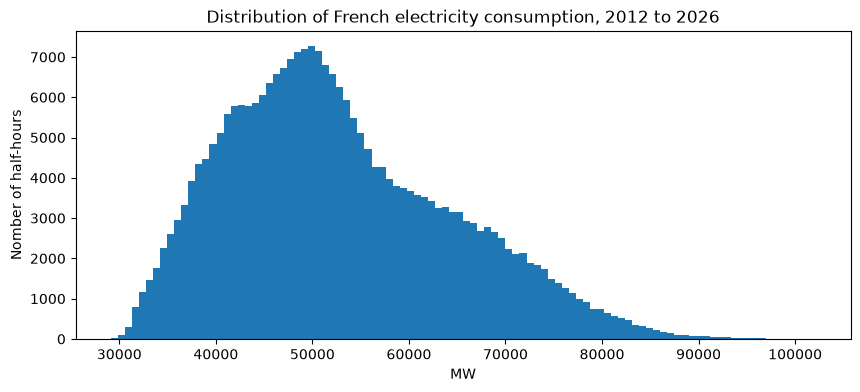

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(cons["consumption_mw"], bins=100)
ax.set_xlabel("MW")
ax.set_ylabel("Nomber of half-hours")
ax.set_title("Distribution of French electricity consumption, 2012 to 2026")
plt.show()

### Weather

In [9]:
read_sql(
    """
    SELECT city,
           min(temperature_c) AS min_c,
           round(avg(temperature_c)::numeric, 1) AS mean_c,
           max(temperature_c) AS max_c
    FROM weather
    GROUP BY city
    ORDER BY city
    """
)

,city,min_c,mean_c,max_c
0,bordeaux,-7.6,14.4,41.7
1,lille,-10.3,11.5,38.1
2,lyon,-9.7,13.2,40.8
3,marseille,-3.8,16.0,37.4
4,nantes,-6.8,13.2,41.2
5,nice,-7.3,16.3,35.3
6,paris,-9.8,12.4,40.7
7,rennes,-6.8,12.5,40.2
8,strasbourg,-13.2,11.9,39.1
9,toulouse,-9.5,14.4,41.2
